# Phase C — Regression Models for Next-Day PM2.5 Forecasting

**City:** Delhi

## Objective

This notebook trains and evaluates regression models for predicting next-day
PM2.5 concentration.

The following models are evaluated:

1. Linear Regression
2. Ridge Regression
3. Lasso Regression

The evaluation metrics are:

- MAE
- RMSE
- R²

A time-ordered train-test split is used.

Ridge and Lasso hyperparameters are selected using time-series
cross-validation.

All models are compared with the persistence baseline.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import (
    LinearRegression,
    RidgeCV,
    LassoCV
)

from sklearn.model_selection import TimeSeriesSplit

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


## Upload the engineered dataset

Upload `delhi_regression_features.csv` (output of Notebook 02), **not** `city_day.csv`.

In [2]:
from google.colab import files

print("Upload delhi_regression_features.csv")
uploaded = files.upload()

Upload delhi_regression_features.csv


Saving delhi_regression_features.csv to delhi_regression_features.csv


In [3]:
INPUT_FILE = "delhi_regression_features.csv"

df = pd.read_csv(INPUT_FILE)

df["Date"] = pd.to_datetime(df["Date"])

df = df.sort_values("Date").reset_index(drop=True)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

print(
    "Date range:",
    df["Date"].min(),
    "to",
    df["Date"].max()
)

print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset loaded successfully.
Shape: (2006, 15)
Date range: 2015-01-01 00:00:00 to 2020-06-30 00:00:00

Columns:
['Date', 'PM2.5_current', 'PM2.5_lag1', 'PM2.5_lag2', 'PM2.5_lag3', 'PM2.5_lag7', 'PM2.5_lag14', 'PM2.5_roll3_mean', 'PM2.5_roll7_mean', 'PM2.5_roll14_mean', 'PM2.5_roll7_std', 'month', 'day_of_week', 'day_of_year', 'PM2.5_tomorrow']


,Date,PM2.5_current,PM2.5_lag1,PM2.5_lag2,PM2.5_lag3,PM2.5_lag7,PM2.5_lag14,PM2.5_roll3_mean,PM2.5_roll7_mean,PM2.5_roll14_mean,PM2.5_roll7_std,month,day_of_week,day_of_year,PM2.5_tomorrow
0,2015-01-01,313.22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,3,1,186.18
1,2015-01-02,186.18,313.22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,4,2,87.18
2,2015-01-03,87.18,186.18,313.22,NaN,NaN,NaN,195.526667,NaN,NaN,NaN,1,5,3,151.84
3,2015-01-04,151.84,87.18,186.18,313.22,NaN,NaN,141.733333,NaN,NaN,NaN,1,6,4,146.60
4,2015-01-05,146.60,151.84,87.18,186.18,NaN,NaN,128.540000,NaN,NaN,NaN,1,0,5,149.58


In [4]:
FEATURES = [
    "PM2.5_current",
    "PM2.5_lag1",
    "PM2.5_lag2",
    "PM2.5_lag3",
    "PM2.5_lag7",
    "PM2.5_lag14",
    "PM2.5_roll3_mean",
    "PM2.5_roll7_mean",
    "PM2.5_roll14_mean",
    "PM2.5_roll7_std",
    "month",
    "day_of_week",
    "day_of_year"
]

TARGET = "PM2.5_tomorrow"

required_columns = (
    ["Date"] +
    FEATURES +
    [TARGET]
)

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        "Wrong input file. Missing columns: "
        + str(missing_columns)
    )

print("Correct engineered dataset loaded.")
print("All required columns found.")

Correct engineered dataset loaded.
All required columns found.


In [5]:
X = df[FEATURES].copy()
y = df[TARGET].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print(
    "Missing predictor values:",
    X.isna().sum().sum()
)

print(
    "Missing target values:",
    y.isna().sum()
)

X shape: (2006, 13)
y shape: (2006,)
Missing predictor values: 96
Missing target values: 0


## Time-Ordered Train-Test Split

Data through 31 December 2019 is used for training.

Data from 2020 is reserved for testing.

Random splitting is avoided because it would mix past and future
observations.

The same test dates are used for the persistence baseline and all regression
models.

In [6]:
TRAIN_END = pd.Timestamp("2019-12-31")

train_mask = df["Date"] <= TRAIN_END
test_mask = df["Date"] > TRAIN_END

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

dates_train = df.loc[
    train_mask,
    "Date"
].copy()

dates_test = df.loc[
    test_mask,
    "Date"
].copy()

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print(
    "\nTraining:",
    dates_train.min().date(),
    "to",
    dates_train.max().date()
)

print(
    "Testing:",
    dates_test.min().date(),
    "to",
    dates_test.max().date()
)

Training samples: 1824
Testing samples: 182

Training: 2015-01-01 to 2019-12-31
Testing: 2020-01-01 to 2020-06-30


In [7]:
assert len(X_train) > 0
assert len(X_test) > 0

assert dates_train.max() < dates_test.min()

assert y_train.isna().sum() == 0
assert y_test.isna().sum() == 0

print("Time-ordered split verification PASSED.")

Time-ordered split verification PASSED.


In [8]:
def evaluate_model(name, y_true, y_pred):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

## Persistence Baseline

The persistence model assumes:

**Tomorrow's PM2.5 = Today's PM2.5**

This is the benchmark against which the regression models are evaluated.

In [9]:
persistence_pred = X_test["PM2.5_current"].copy()

valid_persistence = (
    persistence_pred.notna()
    & y_test.notna()
)

persistence_results = evaluate_model(
    "Persistence Baseline",
    y_test.loc[valid_persistence],
    persistence_pred.loc[valid_persistence]
)

print("Persistence Baseline Results")
print(persistence_results)

Persistence Baseline Results
{'Model': 'Persistence Baseline', 'MAE': 19.158186813186813, 'RMSE': np.float64(28.002480100131162), 'R2': 0.7045883903268023}


## Linear Regression

In [10]:
linear_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LinearRegression()
    )
])

linear_model.fit(
    X_train,
    y_train
)

linear_pred = linear_model.predict(
    X_test
)

linear_results = evaluate_model(
    "Linear Regression",
    y_test,
    linear_pred
)

print("Linear Regression Results")
print(linear_results)

Linear Regression Results
{'Model': 'Linear Regression', 'MAE': 18.126579328658504, 'RMSE': np.float64(24.99952524773345), 'R2': 0.764550329429789}


## Time-Series Cross-Validation

In [11]:
tscv = TimeSeriesSplit(
    n_splits=5
)

print(
    "TimeSeriesSplit folds:",
    tscv.n_splits
)

TimeSeriesSplit folds: 5


## Ridge Regression

In [12]:
ridge_alphas = np.logspace(
    -3,
    3,
    50
)

ridge_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        RidgeCV(
            alphas=ridge_alphas,
            cv=tscv,
            scoring="neg_mean_absolute_error"
        )
    )
])

ridge_model.fit(
    X_train,
    y_train
)

ridge_pred = ridge_model.predict(
    X_test
)

ridge_results = evaluate_model(
    "Ridge Regression",
    y_test,
    ridge_pred
)

print("Ridge Regression Results")
print(ridge_results)

Ridge Regression Results
{'Model': 'Ridge Regression', 'MAE': 18.128631198394846, 'RMSE': np.float64(24.99894081145303), 'R2': 0.7645613379365401}


In [13]:
best_ridge_alpha = (
    ridge_model
    .named_steps["model"]
    .alpha_
)

print(
    "Best Ridge alpha:",
    best_ridge_alpha
)

Best Ridge alpha: 0.49417133613238334


## Lasso Regression

In [14]:
lasso_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LassoCV(
            alphas=np.logspace(
                -3,
                2,
                100
            ),
            cv=tscv,
            max_iter=50000
        )
    )
])

lasso_model.fit(
    X_train,
    y_train
)

lasso_pred = lasso_model.predict(
    X_test
)

lasso_results = evaluate_model(
    "Lasso Regression",
    y_test,
    lasso_pred
)

print("Lasso Regression Results")
print(lasso_results)

Lasso Regression Results
{'Model': 'Lasso Regression', 'MAE': 18.13394567286214, 'RMSE': np.float64(25.00011774062641), 'R2': 0.7645391689050834}


In [15]:
best_lasso_alpha = (
    lasso_model
    .named_steps["model"]
    .alpha_
)

print(
    "Best Lasso alpha:",
    best_lasso_alpha
)

Best Lasso alpha: 0.1484968262254465


## Final Comparison

In [16]:
results = pd.DataFrame([
    persistence_results,
    linear_results,
    ridge_results,
    lasso_results
])

results = (
    results
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("FINAL MODEL COMPARISON")

display(
    results.round(3)
)

FINAL MODEL COMPARISON


,Model,MAE,RMSE,R2
0,Ridge Regression,18.129,24.999,0.765
1,Linear Regression,18.127,25.000,0.765
2,Lasso Regression,18.134,25.000,0.765
3,Persistence Baseline,19.158,28.002,0.705


## Improvement vs Persistence

In [17]:
baseline_mae = persistence_results["MAE"]
baseline_rmse = persistence_results["RMSE"]

comparison = results.copy()

comparison["MAE_Improvement_%"] = (
    (
        baseline_mae
        - comparison["MAE"]
    )
    / baseline_mae
    * 100
)

comparison["RMSE_Improvement_%"] = (
    (
        baseline_rmse
        - comparison["RMSE"]
    )
    / baseline_rmse
    * 100
)

display(
    comparison.round(2)
)

,Model,MAE,RMSE,R2,MAE_Improvement_%,RMSE_Improvement_%
0,Ridge Regression,18.13,25.0,0.76,5.37,10.73
1,Linear Regression,18.13,25.0,0.76,5.38,10.72
2,Lasso Regression,18.13,25.0,0.76,5.35,10.72
3,Persistence Baseline,19.16,28.0,0.70,0.00,0.00


## Best Model

In [18]:
regression_results = results[
    results["Model"] != "Persistence Baseline"
].copy()

best_row = (
    regression_results
    .sort_values("RMSE")
    .iloc[0]
)

best_model_name = best_row["Model"]

print(
    "Best regression model:",
    best_model_name
)

print(
    "MAE:",
    round(best_row["MAE"], 3)
)

print(
    "RMSE:",
    round(best_row["RMSE"], 3)
)

print(
    "R²:",
    round(best_row["R2"], 3)
)

Best regression model: Ridge Regression
MAE: 18.129
RMSE: 24.999
R²: 0.765


## Actual vs Predicted Plot

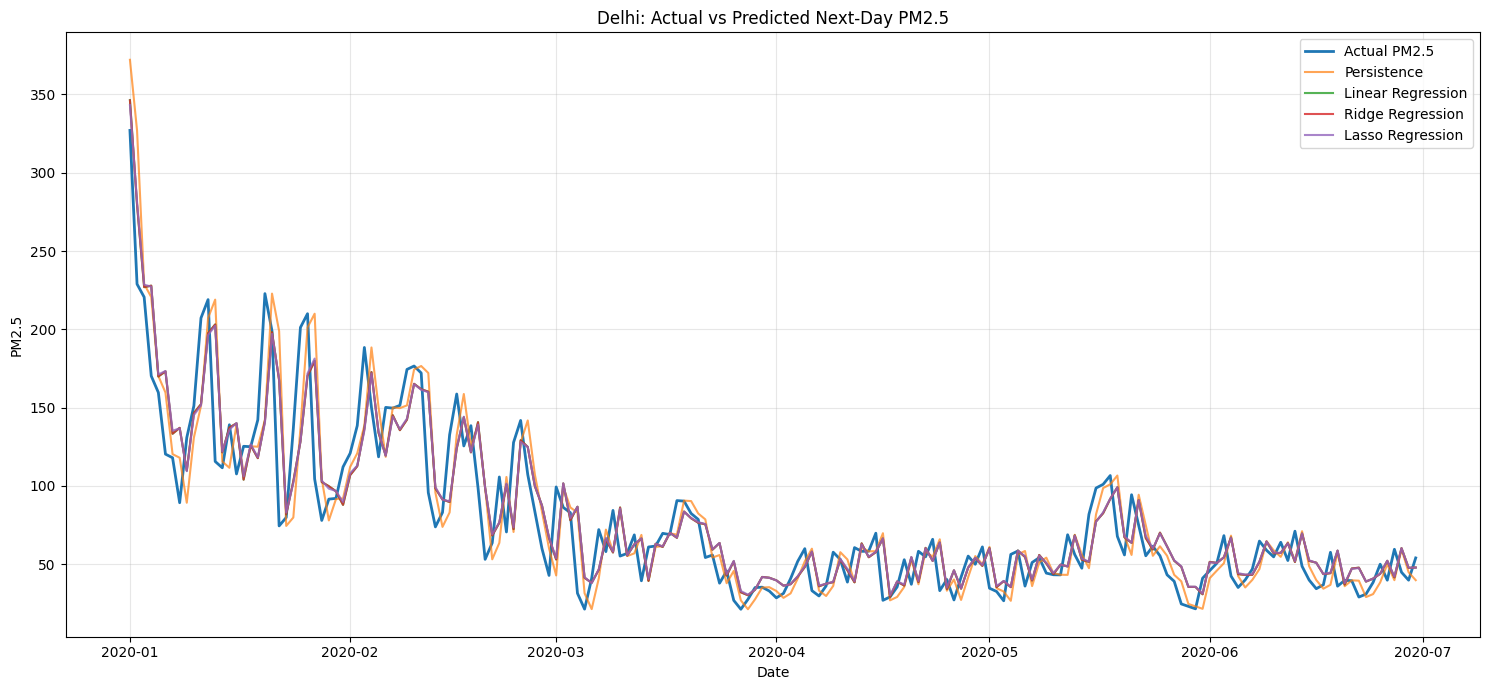

In [19]:
plt.figure(figsize=(15, 7))

plt.plot(
    dates_test.values,
    y_test.values,
    label="Actual PM2.5",
    linewidth=2
)

plt.plot(
    dates_test.values,
    persistence_pred.values,
    label="Persistence",
    alpha=0.7
)

plt.plot(
    dates_test.values,
    linear_pred,
    label="Linear Regression",
    alpha=0.8
)

plt.plot(
    dates_test.values,
    ridge_pred,
    label="Ridge Regression",
    alpha=0.8
)

plt.plot(
    dates_test.values,
    lasso_pred,
    label="Lasso Regression",
    alpha=0.8
)

plt.xlabel("Date")
plt.ylabel("PM2.5")

plt.title(
    "Delhi: Actual vs Predicted Next-Day PM2.5"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Best Model Scatter Plot

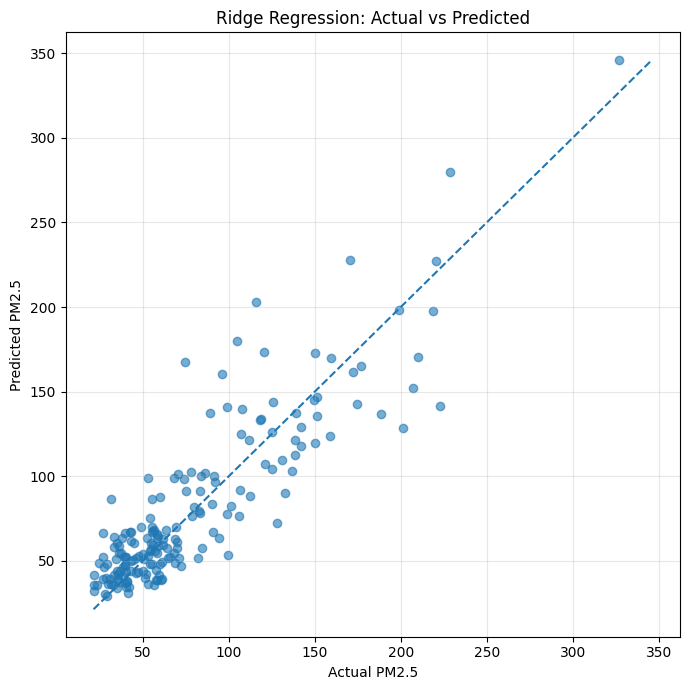

In [20]:
prediction_map = {
    "Linear Regression": linear_pred,
    "Ridge Regression": ridge_pred,
    "Lasso Regression": lasso_pred
}

best_predictions = prediction_map[
    best_model_name
]

plt.figure(figsize=(7, 7))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.6
)

minimum = min(
    y_test.min(),
    best_predictions.min()
)

maximum = max(
    y_test.max(),
    best_predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "--"
)

plt.xlabel("Actual PM2.5")
plt.ylabel("Predicted PM2.5")

plt.title(
    f"{best_model_name}: Actual vs Predicted"
)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Residual Plot

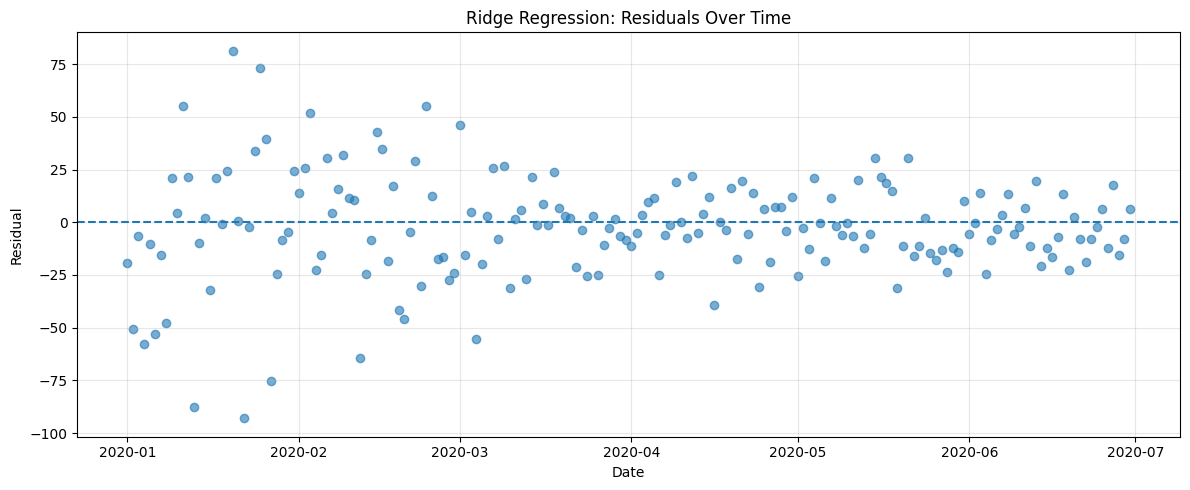

In [21]:
residuals = (
    y_test.values
    - best_predictions
)

plt.figure(figsize=(12, 5))

plt.scatter(
    dates_test.values,
    residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Date")
plt.ylabel("Residual")

plt.title(
    f"{best_model_name}: Residuals Over Time"
)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Coefficient Comparison

In [22]:
coefficient_table = pd.DataFrame({
    "Feature": FEATURES,

    "Linear":
        linear_model
        .named_steps["model"]
        .coef_,

    "Ridge":
        ridge_model
        .named_steps["model"]
        .coef_,

    "Lasso":
        lasso_model
        .named_steps["model"]
        .coef_
})

coefficient_table["Ridge_Abs"] = (
    coefficient_table["Ridge"].abs()
)

coefficient_table = (
    coefficient_table
    .sort_values(
        "Ridge_Abs",
        ascending=False
    )
)

display(coefficient_table)

,Feature,Linear,Ridge,Lasso,Ridge_Abs
0,PM2.5_current,57.453056,58.191897,66.343350,58.191897
6,PM2.5_roll3_mean,29.713407,27.282995,0.000000,27.282995
1,PM2.5_lag1,-24.451612,-23.524683,-12.499007,23.524683
8,PM2.5_roll14_mean,11.545640,11.492044,10.381110,11.492044
2,PM2.5_lag2,2.570334,3.381723,11.648738,3.381723
7,PM2.5_roll7_mean,-3.049599,-2.886646,0.000000,2.886646
9,PM2.5_roll7_std,-2.788765,-2.789192,-2.369373,2.789192
5,PM2.5_lag14,2.272555,2.283991,2.370304,2.283991
12,day_of_year,1.883790,1.936155,1.790251,1.936155
10,month,1.766289,1.721094,1.742314,1.721094


## Save Results

In [23]:
predictions = pd.DataFrame({
    "Date": dates_test.values,
    "Actual_PM2.5": y_test.values,
    "Persistence":
        persistence_pred.values,
    "Linear_Regression":
        linear_pred,
    "Ridge_Regression":
        ridge_pred,
    "Lasso_Regression":
        lasso_pred
})

results.to_csv(
    "regression_model_comparison.csv",
    index=False
)

comparison.to_csv(
    "regression_baseline_improvement.csv",
    index=False
)

predictions.to_csv(
    "regression_predictions.csv",
    index=False
)

coefficient_table.to_csv(
    "regression_coefficients.csv",
    index=False
)

print("All results saved successfully.")

All results saved successfully.


## Automatic Final Summary

In [24]:
best_regression = (
    regression_results
    .sort_values("RMSE")
    .iloc[0]
)

rmse_improvement = (
    (
        persistence_results["RMSE"]
        - best_regression["RMSE"]
    )
    / persistence_results["RMSE"]
    * 100
)

print("=" * 60)
print("PHASE C REGRESSION SUMMARY")
print("=" * 60)

print(
    "\nBest model:",
    best_regression["Model"]
)

print(
    "MAE:",
    round(best_regression["MAE"], 3)
)

print(
    "RMSE:",
    round(best_regression["RMSE"], 3)
)

print(
    "R²:",
    round(best_regression["R2"], 3)
)

print(
    "\nPersistence RMSE:",
    round(
        persistence_results["RMSE"],
        3
    )
)

print(
    "RMSE improvement over persistence:",
    round(rmse_improvement, 2),
    "%"
)

print(
    "\nBest Ridge alpha:",
    best_ridge_alpha
)

print(
    "Best Lasso alpha:",
    best_lasso_alpha
)

PHASE C REGRESSION SUMMARY

Best model: Ridge Regression
MAE: 18.129
RMSE: 24.999
R²: 0.765

Persistence RMSE: 28.002
RMSE improvement over persistence: 10.73 %

Best Ridge alpha: 0.49417133613238334
Best Lasso alpha: 0.1484968262254465


## Conclusion

*Fill in only after running the notebook, using the actual outputs.*

Linear Regression, Ridge Regression and Lasso Regression were evaluated for
next-day PM2.5 forecasting in Delhi.

A time-ordered train-test split was used to prevent future observations from
entering model training.

Missing predictor values were handled using median imputation fitted only on
the training data. Ridge and Lasso regularisation parameters were selected
using time-series cross-validation.

### Results

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| Persistence Baseline | [VALUE] | [VALUE] | [VALUE] |
| Linear Regression | [VALUE] | [VALUE] | [VALUE] |
| Ridge Regression | [VALUE] | [VALUE] | [VALUE] |
| Lasso Regression | [VALUE] | [VALUE] | [VALUE] |

The best regression model was **[MODEL]**, with:

- MAE = **[VALUE]**
- RMSE = **[VALUE]**
- R² = **[VALUE]**

Its RMSE was **[VALUE]% [lower/higher]** than the persistence baseline.

This comparison determines whether the engineered lag, rolling and calendar
features provide useful predictive information beyond the simple persistence
forecast.